# Toronto bus delays, Jan–Jun 2022: what causes them, and when?

**Data:** TTC bus delay log, 1 Jan – 30 Jun 2022 ([Kaggle: reihanenamdari/toronto-bus-delay-2022](https://www.kaggle.com/datasets/reihanenamdari/toronto-bus-delay-2022)), one row per reported incident.
Raw file: `data/toronto/ttc-bus-delay-data-2022.csv` (read only, never modified).

In [1]:
import json, urllib.request, zipfile
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ACCENT, MUTED = "#1f6feb", "#9aa4b2"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "grid.color": "#e5e7eb", "grid.linewidth": 0.8,
    "axes.grid.axis": "y", "legend.frameon": False,
})

## What does the raw data look like?

In [2]:
raw = pd.read_csv("data/toronto/ttc-bus-delay-data-2022.csv")
print(raw.shape, "| exact duplicate rows:", raw.duplicated().sum())
display(raw.head())
display(raw.isna().mean().round(3).to_frame("null rate").T)
display(raw.describe())
print("Direction codes:", raw["Direction"].value_counts(dropna=False).to_dict())
print("Min Delay = 0:", f"{(raw['Min Delay'] == 0).mean():.1%}", "| >= 900 min:", (raw["Min Delay"] >= 900).sum(),
      "| Vehicle = 0:", f"{(raw['Vehicle'] == 0).mean():.1%}")
print("corr(Min Delay, Min Gap):", round(raw["Min Delay"].corr(raw["Min Gap"]), 2))

(27351, 10) | exact duplicate rows: 154


,Date,Route,Time,Day,Location,Incident,Min Delay,Min Gap,Direction,Vehicle
0,1-Jan-22,320,02:00,Saturday,YONGE AND DUNDAS,General Delay,0,0,NaN,8531
1,1-Jan-22,325,02:00,Saturday,OVERLEA AND THORCLIFFE,Diversion,131,161,W,8658
2,1-Jan-22,320,02:00,Saturday,YONGE AND STEELES,Operations - Operator,17,20,S,0
3,1-Jan-22,320,02:07,Saturday,YONGE AND STEELES,Operations - Operator,4,11,S,0
4,1-Jan-22,320,02:13,Saturday,YONGE AND STEELES,Operations - Operator,4,8,S,0


,Date,Route,Time,Day,Location,Incident,Min Delay,Min Gap,Direction,Vehicle
null rate,0.0,0.006,0.0,0.0,0.0,0.0,0.0,0.0,0.204,0.0


,Min Delay,Min Gap,Vehicle
count,27351.000000,27351.000000,27351.000000
mean,20.298417,32.876714,5410.169427
std,49.636736,51.293913,4616.285325
min,0.000000,0.000000,0.000000
25%,9.000000,17.000000,1394.000000
50%,11.000000,22.000000,7940.000000
75%,20.000000,36.000000,8523.000000
max,999.000000,999.000000,93561.000000


Direction codes: {'N': 5968, nan: 5577, 'S': 5450, 'E': 5197, 'W': 4841, 'B': 309, 'J': 2, 'Q': 2, '/': 1, 'D': 1, 'I': 1, '2': 1, '6': 1}
Min Delay = 0: 4.8% | >= 900 min: 13 | Vehicle = 0: 12.3%
corr(Min Delay, Min Gap): 0.96


**Data-quality flags**
- 154 exact duplicate rows: dropped below.
- `Direction` is 20% missing and has stray codes (`J`, `Q`, `/`, `2`, …) besides N/S/E/W and `B` (both ways): not used here.
- `Route` is 0.6% missing; those rows are left out of the route chart only.
- `Min Delay` runs to 999 minutes; a few values ≥ 900 look like caps or entry errors, so charts of totals are sensitive to them.
- `Min Gap` (gap between buses) moves almost one-for-one with `Min Delay` (r ≈ 0.96), so it adds little on its own.
- `Vehicle = 0` looks like "unknown vehicle", not a real ID.

In [3]:
df = raw.drop_duplicates().assign(
    Date=lambda d: pd.to_datetime(d["Date"], format="%d-%b-%y"),
    hour=lambda d: pd.to_datetime(d["Time"], format="%H:%M").dt.hour,
)
assert df["Date"].between("2022-01-01", "2022-06-30").all()
print(f"{len(df):,} incidents, {df['Date'].min():%d %b} – {df['Date'].max():%d %b %Y}, {df['Route'].nunique()} routes")

27,197 incidents, 01 Jan – 30 Jun 2022, 223 routes


## How long is a typical delay?

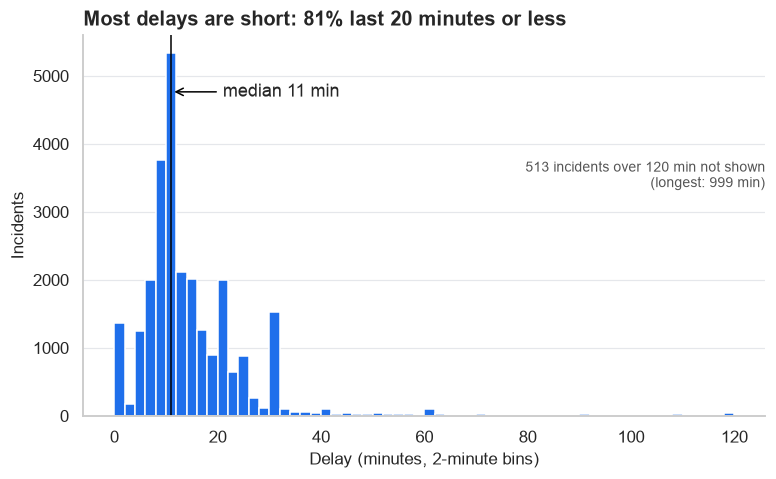

In [4]:
d = df["Min Delay"]
fig, ax = plt.subplots()
ax.hist(d[d <= 120], bins=range(0, 122, 2), color=ACCENT)
ax.axvline(d.median(), color="black", lw=1)
ax.annotate(f"median {d.median():.0f} min", xy=(d.median(), ax.get_ylim()[1] * 0.85), xytext=(d.median() + 10, ax.get_ylim()[1] * 0.85),
            arrowprops=dict(arrowstyle="->", color="black"), va="center")
ax.text(1, 0.6, f"{(d > 120).sum():,} incidents over 120 min not shown\n(longest: {d.max()} min)",
        transform=ax.transAxes, ha="right", color="#555", fontsize=9)
ax.set(title=f"Most delays are short: {(d <= 20).mean():.0%} last 20 minutes or less",
       xlabel="Delay (minutes, 2-minute bins)", ylabel="Incidents")
plt.show()

The spikes at 10, 20 and 30 minutes are reporting round-offs. The typical delay is a few minutes, but a long tail of rare, hour-plus incidents drives most of the lost time (next chart).

## Which causes cost riders the most time?

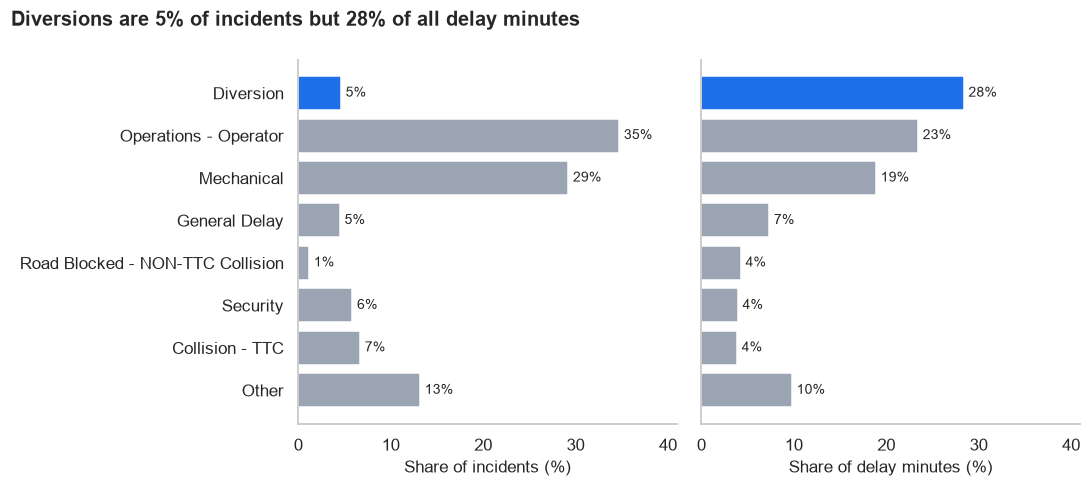

In [5]:
inc = df.groupby("Incident")["Min Delay"].agg(incidents="size", minutes="sum")
top = inc.nlargest(7, "minutes").index
inc = inc.groupby(inc.index.where(inc.index.isin(top), "Other")).sum()
share = (inc / inc.sum() * 100).sort_values("minutes")
share = pd.concat([share.loc[["Other"]], share.drop("Other")])  # "Other" sits at the bottom
colors = [ACCENT if i == "Diversion" else MUTED for i in share.index]
div = share.loc["Diversion"]

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(10, 4.5))
for ax, col, label in zip(axes, ["incidents", "minutes"], ["Share of incidents (%)", "Share of delay minutes (%)"]):
    bars = ax.barh(share.index, share[col], color=colors)
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9)
    ax.set(xlabel=label, xlim=(0, share.values.max() * 1.18))
    ax.grid(False)
fig.suptitle(f"Diversions are {div.incidents:.0f}% of incidents but {div.minutes:.0f}% of all delay minutes",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Operator and mechanical problems happen most often, but each one is short; diversions are rare and long, so they are the biggest single source of lost time.

## What time of day do delays happen?

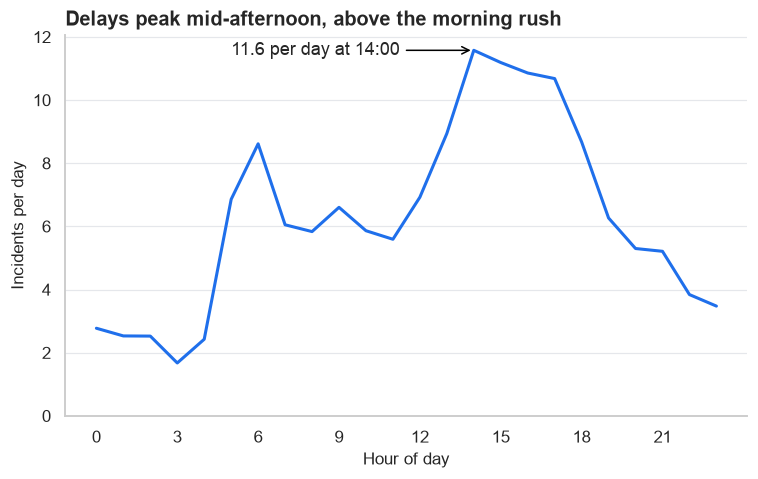

In [6]:
by_hour = df.groupby("hour").size() / df["Date"].nunique()
peak = by_hour.idxmax()
fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour.values, color=ACCENT, lw=2)
ax.annotate(f"{by_hour.max():.1f} per day at {peak}:00", xy=(peak, by_hour.max()), xytext=(peak - 9, by_hour.max()),
            arrowprops=dict(arrowstyle="->", color="black"), va="center")
ax.set(title="Delays peak mid-afternoon, above the morning rush",
       xlabel="Hour of day", ylabel="Incidents per day", xticks=range(0, 24, 3), ylim=(0, None))
plt.show()

The 2–6 pm window is the worst part of the day; the morning has a smaller spike around 6 am.

## Which days of the week are worst?

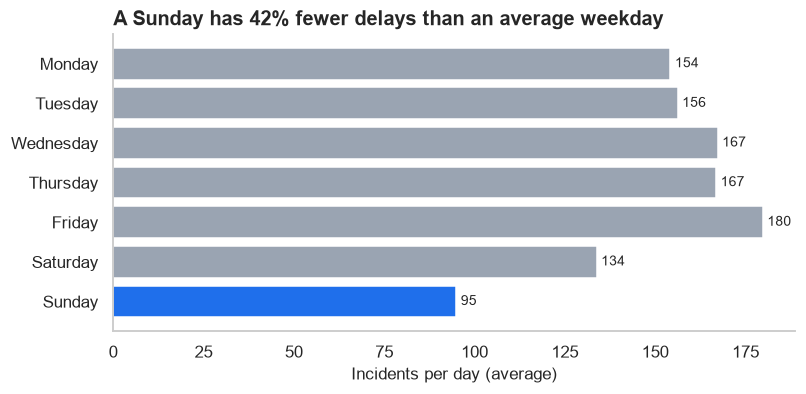

In [7]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
per_day = (df.groupby("Day").size() / df.groupby("Day")["Date"].nunique()).reindex(order)
weekday = per_day[:5].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(order[::-1], per_day[::-1], color=[ACCENT if x == "Sunday" else MUTED for x in order[::-1]])
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.grid(False)
ax.set(title=f"A Sunday has {1 - per_day['Sunday'] / weekday:.0%} fewer delays than an average weekday",
       xlabel="Incidents per day (average)")
plt.show()

Delays follow service volume: weekdays (Friday highest) far outpace the weekend.

## Did delays change over the six months?

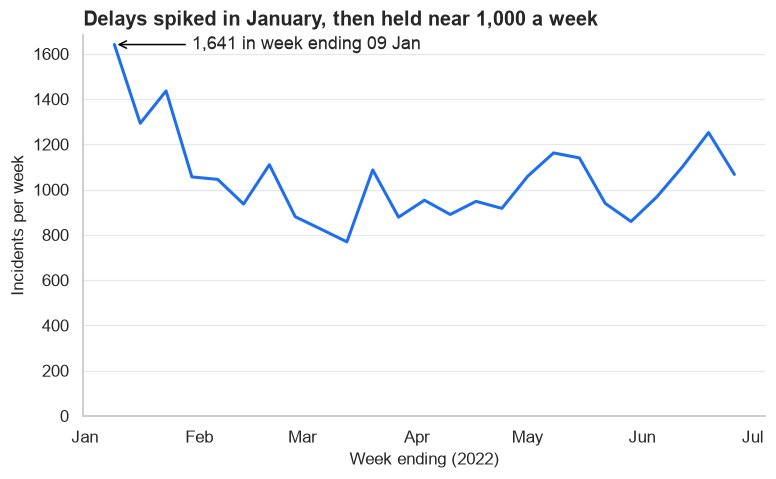

In [8]:
weekly = df.set_index("Date").resample("W").size().iloc[1:-1]  # drop the partial first and last weeks
fig, ax = plt.subplots()
ax.plot(weekly.index, weekly.values, color=ACCENT, lw=2)
ax.annotate(f"{weekly.max():,} in week ending {weekly.idxmax():%d %b}", xy=(weekly.idxmax(), weekly.max()),
            xytext=(weekly.idxmax() + pd.Timedelta(days=21), weekly.max()), arrowprops=dict(arrowstyle="->", color="black"), va="center")
ax.set(title="Delays spiked in January, then held near 1,000 a week",
       xlabel="Week ending (2022)", ylabel="Incidents per week", ylim=(0, None))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.show()

After a rough January, weekly delays stay in a steady band through June, with no clear upward or downward trend.

## Are delays concentrated on a few routes?

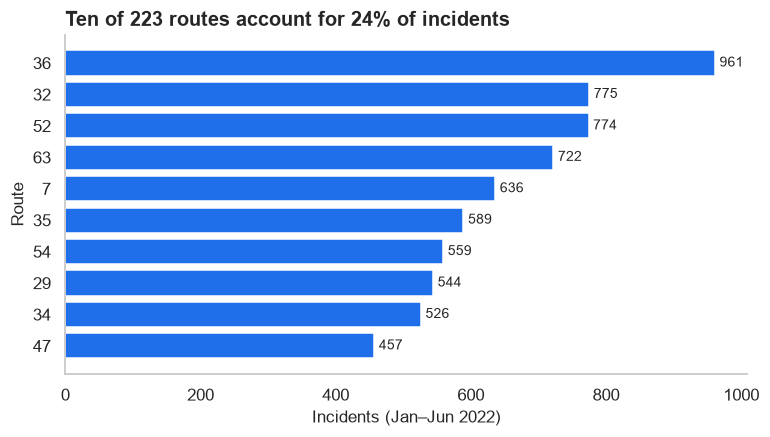

In [9]:
routes = df["Route"].value_counts()
top10 = routes.head(10)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(top10.index[::-1], top10[::-1], color=ACCENT)
ax.bar_label(bars, padding=3, fontsize=9)
ax.grid(False)
ax.set(title=f"Ten of {len(routes)} routes account for {top10.sum() / routes.sum():.0%} of incidents",
       xlabel="Incidents (Jan–Jun 2022)", ylabel="Route")
plt.show()

Raw counts favour long, busy routes, so this shows where delays happen, not which routes are least reliable per trip.

# Part 2: building the route-hour table

Raw counts mostly show which routes run the most buses. To compare like with like, part 2 builds one row per **route × hour**: how many delays happened, how many trips were scheduled, and the calendar, weather and route facts for that hour. The model notebook (`toronto_model.ipynb`) reads this table.

**Outside data**, downloaded once if missing:
- Hourly weather for downtown Toronto from [Open-Meteo](https://open-meteo.com/en/docs/historical-forecast-api) (`data/toronto/weather_2022.csv`).
- The TTC schedule (GTFS) from [Toronto Open Data](https://open.toronto.ca/dataset/ttc-routes-and-schedules/) (`data/toronto/opendata_ttc_schedules.zip`). Only the **current** schedule is published, so 2022 trips are approximated by today's timetable.

In [10]:
DATA = Path("data/toronto")
W_CSV, GTFS_ZIP = DATA / "weather_2022.csv", DATA / "opendata_ttc_schedules.zip"
W_COLS = {"temperature_2m": "temp_c", "precipitation": "precip_mm", "rain": "rain_mm", "snowfall": "snowfall_cm",
          "snow_depth": "snow_depth_m", "wind_speed_10m": "wind_kmh", "wind_gusts_10m": "wind_gust_kmh", "visibility": "visibility_m"}
if not W_CSV.exists():
    # requested in UTC: Open-Meteo's "local" times use one fixed offset and ignore the March clock change
    url = ("https://historical-forecast-api.open-meteo.com/v1/forecast?latitude=43.6532&longitude=-79.3832"
           "&start_date=2021-12-31&end_date=2022-07-01&timezone=GMT&hourly=" + ",".join(W_COLS))
    with urllib.request.urlopen(url) as r:
        pd.DataFrame(json.load(r)["hourly"]).to_csv(W_CSV, index=False)
if not GTFS_ZIP.exists():
    urllib.request.urlretrieve("https://ckan0.cf.opendata.inter.prod-toronto.ca/dataset/7795b45e-e65a-4465-81fc-c36b9dfff169"
                               "/resource/cfb6b2b8-6191-41e3-bda1-b175c51148cb/download/opendata_ttc_schedules.zip", GTFS_ZIP)

weather = (pd.read_csv(W_CSV).rename(columns=W_COLS)
           .assign(ts=lambda w: pd.to_datetime(w["time"]).dt.tz_localize("UTC").dt.tz_convert("America/Toronto"))
           .drop(columns="time").drop_duplicates("ts"))
weather = weather[weather.ts.dt.year.eq(2022) & weather.ts.dt.month.le(6)].reset_index(drop=True)  # local 1 Jan – 30 Jun
print(f"weather: {len(weather):,} hours, {weather.ts.min():%d %b} – {weather.ts.max():%d %b %Y}; missing values: {weather.isna().sum().sum()}")

weather: 4,343 hours, 01 Jan – 30 Jun 2022; missing values: 0


In [11]:
assert weather["ts"].is_unique and weather["ts"].dt.tz is not None
assert len(weather) >= 4343                      # 181 days x 24 h, minus the DST hour
assert weather.loc[weather.ts.dt.date.astype(str) == "2022-01-17", "snowfall_cm"].sum() > 10
assert GTFS_ZIP.stat().st_size > 10_000_000

## Calendar: which days were unusual?

Each day gets a service type and flags for holidays, the university and school terms, and the Omicron wave.
- **Ontario public holidays:** 1 Jan, 21 Feb (Family Day), 15 Apr (Good Friday), 23 May (Victoria Day) ([ontario.ca](https://www.ontario.ca/document/your-guide-employment-standards-act-0/public-holidays)). The TTC runs its Sunday schedule on these days. 3 Jan is *not* a holiday: the TTC went back to regular service on 2 Jan ([TTC notice](https://www.ttc.ca/news/2020/December/TTC-Service-Schedules-for-New-Years-Eve-and-New-Years-Day)).
- **UofT, Faculty of Arts & Science, 2021–22:** winter classes 10 Jan – 8 Apr, reading week 21–25 Feb, exams 11–29 Apr, summer term from 9 May, break otherwise ([A&S academic dates](https://www.artsci.utoronto.ca/current/dates-deadlines/academic-dates); the 2021–22 page is no longer posted, so these dates could not be re-checked). Classes were online until 6 Feb and moved back in person on 7 Feb ([U of T, 19 Jan 2022](https://www.utm.utoronto.ca/node/8002)).
- **Toronto public schools (TDSB):** remote 5–14 Jan, back in class 17 Jan ([CTV](https://toronto.ctvnews.ca/ontario-schools-to-reopen-for-in-person-learning-on-jan-17-1.5734963)). Off 1–4 Jan, during March break 14–18 Mar, on Easter Monday 18 Apr, on weekends and holidays, and after the last elementary day, 30 Jun ([TDSB 2021–22 calendar](https://www.tdsb.on.ca/Portals/0/EarlyYears/docs/May-20-2021-TDSB-2021-22-Schoo-Year-Calendar-Pending-Ministry-Approval-revised.pdf)). PA days differ by school and are left out.
- **Omicron:** all of January is flagged, as a control. Staffing shortages, remote schools and the 17 Jan snowstorm make it unlike the rest of the half-year. This one is our call.

In [12]:
HOLIDAYS = {date(2022, 1, 1), date(2022, 2, 21), date(2022, 4, 15), date(2022, 5, 23)}

def between(d, start, end):
    return date.fromisoformat(start) <= d <= date.fromisoformat(end)

def day_info(d):
    holiday = d in HOLIDAYS
    day_type = "sunday" if holiday or d.weekday() == 6 else "saturday" if d.weekday() == 5 else "weekday"
    if between(d, "2022-02-21", "2022-02-25"): uoft_phase = "reading_week"
    elif between(d, "2022-01-10", "2022-04-08"): uoft_phase = "classes"
    elif between(d, "2022-04-11", "2022-04-29"): uoft_phase = "exams"
    elif d >= date(2022, 5, 9): uoft_phase = "summer"
    else: uoft_phase = "break"
    if (day_type != "weekday" or d <= date(2022, 1, 4) or between(d, "2022-03-14", "2022-03-18")
            or d == date(2022, 4, 18) or d > date(2022, 6, 30)):
        school = "off"
    elif between(d, "2022-01-05", "2022-01-14"): school = "remote"
    else: school = "in_person"
    return dict(day_type=day_type, holiday=holiday, uoft_phase=uoft_phase, uoft_online=d < date(2022, 2, 7),
                school=school, omicron=d.month == 1)

In [13]:
assert day_info(date(2022, 2, 21))["day_type"] == "sunday" and day_info(date(2022, 2, 21))["holiday"]
assert day_info(date(2022, 2, 22))["uoft_phase"] == "reading_week"
assert day_info(date(2022, 3, 15))["school"] == "off"
assert day_info(date(2022, 1, 12))["school"] == "remote" and day_info(date(2022, 1, 12))["omicron"]
assert day_info(date(2022, 6, 4))["day_type"] == "saturday"
assert day_info(date(2022, 1, 3))["day_type"] == "weekday"           # TTC ran regular service; not a public holiday
assert day_info(date(2022, 4, 18))["school"] == "off" and not day_info(date(2022, 4, 18))["holiday"]  # Easter Monday
assert day_info(date(2022, 6, 30))["school"] == "in_person" and not day_info(date(2022, 2, 7))["uoft_online"]

## Schedule: how many trips does each route run per hour?

Delay counts mean little without knowing how much service ran, so every route-hour gets its **scheduled trips** (exposure) from the TTC timetable.
- One reference day per service type in the feed (the first Wednesday, Saturday and Sunday), with the feed's added and removed service days applied.
- A trip counts in the hour it leaves its first stop. Times past midnight such as `25:10` belong to hour 1.
- Buses and streetcars only. Subway lines 1–4 share numbers with a few shuttle-bus incidents but aren't bus service.
- The feed covers Nov–Dec 2026, not 2022, so routes added or renumbered since then won't match.

In [14]:
z = zipfile.ZipFile(GTFS_ZIP)
gtfs = lambda name, **kw: pd.read_csv(z.open(f"{name}.txt"), dtype=str, **kw)
routes = gtfs("routes").query("route_type != '1'").assign(route=lambda r: r.route_short_name.str.strip())
trips = gtfs("trips").merge(routes[["route_id", "route"]], on="route_id")
cal, cal_dates = gtfs("calendar"), gtfs("calendar_dates")

def services_on(day):
    ymd, dow = day.strftime("%Y%m%d"), day.strftime("%A").lower()
    on = set(cal.query(f"{dow} == '1' and start_date <= @ymd <= end_date").service_id)
    ex = cal_dates[cal_dates.date == ymd]
    return (on | set(ex[ex.exception_type == "1"].service_id)) - set(ex[ex.exception_type == "2"].service_id)

days = pd.date_range(pd.to_datetime(cal.start_date.min()), periods=7)
ref = {t: next(d for d in days if d.weekday() == wd) for t, wd in [("weekday", 2), ("saturday", 5), ("sunday", 6)]}

st = gtfs("stop_times", usecols=["trip_id", "stop_sequence", "departure_time"]).assign(seq=lambda s: s.stop_sequence.astype(int))
first = st.loc[st.groupby("trip_id").seq.idxmin(), ["trip_id", "departure_time"]]
trips = trips.merge(first, on="trip_id").assign(
    hour=lambda t: t.departure_time.str.split(":").str[0].astype(int) % 24,
    n_stops=lambda t: t.trip_id.map(st.groupby("trip_id").size()))

sched = (pd.concat([trips[trips.service_id.isin(services_on(d))].assign(day_type=t) for t, d in ref.items()])
         .groupby(["route", "day_type", "hour"]).size().rename("trips").reset_index())

shape_km = gtfs("shapes", usecols=["shape_id", "shape_dist_traveled"]).astype({"shape_dist_traveled": float}).groupby("shape_id").shape_dist_traveled.max()
num = pd.to_numeric(routes.set_index("route").route_short_name, errors="coerce")
traits = (trips.assign(length_km=trips.shape_id.map(shape_km)).groupby("route")[["length_km", "n_stops"]].median()
          .loc[lambda t: t.index.isin(sched.route)].reset_index()
          .assign(group=lambda t: np.select([t.route.map(num).between(300, 399), t.route.map(num).between(900, 999)],
                                            ["night", "express"], "regular")))

pos = df[df["Min Delay"] > 0]
match_rate = pos.Route.isin(traits.route).mean()
print(f"reference days: {', '.join(f'{t} {d:%a %d %b %Y}' for t, d in ref.items())}; {len(traits)} routes, {sched.trips.sum():,} trips")
print("unmatched incident routes (top 10):", pos.loc[~pos.Route.isin(traits.route), "Route"].value_counts().head(10).to_dict())

reference days: weekday Wed 04 Nov 2026, saturday Sat 07 Nov 2026, sunday Sun 01 Nov 2026; 226 routes, 99,398 trips
unmatched incident routes (top 10): {'124': 106, '56': 92, '81': 83, '927 HIGHWAY 27': 27, '332': 21, '600': 14, '172': 14, '1': 13, '999': 11, '302': 6}


In [15]:
assert set(sched.day_type) == {"weekday", "saturday", "sunday"}
assert sched.hour.between(0, 23).all() and (sched.trips > 0).all()
assert sched.query("route == '36' and day_type == 'weekday' and hour == 8").trips.iloc[0] > 0
assert traits.route.map(type).eq(str).all()
assert traits.loc[traits.route.str.fullmatch(r"3\d\d"), "group"].eq("night").all()
assert sched.route.isin(traits.route).all() and not traits.route.duplicated().any()
print(f"incident route match rate: {match_rate:.1%}")

incident route match rate: 98.3%


## The table: one row per route and hour

- **Target `n_delays`:** delays longer than 0 minutes in that route-hour.
- **Exposure `trips`:** scheduled trips for that route, service type and hour. Rows with no scheduled trips are dropped, so a route isn't credited with "no delays" while it wasn't running.
- **Recent delays:** `lag1` and `lag3` count the same route's delays in the previous 1 and 3 hours, and `city_lag1` counts all routes in the previous hour. They are computed on the full hourly grid *before* that drop, so "previous hour" always means the clock hour before.
- Hours are Toronto local time. The `2022-03-13 02:00` hour doesn't exist and is skipped.

In [16]:
# shortcut: no fallback for unmatched routes, since the spec only asks for one below a 90% match rate; add it if a new feed matches less
assert match_rate >= 0.9
HOURS = pd.date_range("2022-01-01", "2022-07-01", freq="h", tz="America/Toronto", inclusive="left")
pos_ts = (pos.Date + pd.to_timedelta(pos.hour, unit="h")).dt.tz_localize("America/Toronto", nonexistent="shift_forward", ambiguous=True)
counts = pos.assign(ts=pos_ts).groupby(["Route", "ts"]).size()

grid = pd.MultiIndex.from_product([traits.route, HOURS], names=["route", "ts"]).to_frame(index=False)
grid["n_delays"] = counts.reindex(pd.MultiIndex.from_frame(grid), fill_value=0).to_numpy()
by_route = grid.groupby("route").n_delays
grid["lag1"] = by_route.shift(1, fill_value=0)
grid["lag3"] = grid.lag1 + by_route.shift(2, fill_value=0) + by_route.shift(3, fill_value=0)
grid["city_lag1"] = grid.ts.map(pos_ts.value_counts().reindex(HOURS, fill_value=0).shift(1, fill_value=0))  # all routes, matched or not

days = pd.DataFrame([{"date": d, **day_info(d)} for d in sorted(set(HOURS.date))])
rh = (grid.assign(date=grid.ts.dt.date, hour=grid.ts.dt.hour, weekday=grid.ts.dt.day_of_week)
      .merge(days, on="date")
      .merge(sched, on=["route", "day_type", "hour"], how="left").fillna({"trips": 0})
      .query("trips > 0")
      .merge(weather, on="ts", how="left")
      .merge(traits, on="route")
      .assign(fallback=False, trips=lambda r: r.trips.astype(int))
      .reset_index(drop=True))
unmatched = (~pos.Route.isin(traits.route)).sum()
print(f"{len(rh):,} route-hours with service; {unmatched:,} delays on routes missing from the schedule, "
      f"{len(pos) - unmatched - rh.n_delays.sum():,} in hours with no scheduled trips")

686,398 route-hours with service; 441 delays on routes missing from the schedule, 545 in hours with no scheduled trips


In [17]:
pos = df[df["Min Delay"] > 0]
assert not rh.duplicated(["route", "ts"]).any() and (rh.trips > 0).all()
assert rh.notna().all().all()                    # includes the weather join
assert (rh.loc[rh.holiday, "day_type"] == "sunday").all()
assert not (rh.ts.dt.strftime("%Y-%m-%d %H") == "2022-03-13 02").any()
kept = rh.n_delays.sum()
print(f"incidents kept {kept:,} of {len(pos):,} ({kept / len(pos):.1%}); not kept: {len(pos) - kept:,}")
assert kept / len(pos) >= 0.85
prev_hour = grid.set_index(["route", "ts"]).n_delays.reindex(pd.MultiIndex.from_arrays([rh.route, rh.ts - pd.Timedelta(hours=1)]), fill_value=0)
assert (rh.lag1.to_numpy() == prev_hour.to_numpy()).all()   # lag1 is the clock hour before, even after a no-service gap
rh.to_parquet(DATA / "route_hour.parquet", index=False)

incidents kept 24,912 of 25,898 (96.2%); not kept: 986


# Part 2b: what moves the delay rate?

Every chart below shows **delays per 100 scheduled trips**, so busy routes and busy hours don't win just by running more buses. `n` is the number of distinct days, clock hours or routes behind each bar.

In [18]:
def rates(by, n="ts", data=rh):
    g = data.groupby(by, observed=True)
    return pd.DataFrame({"rate": 100 * g.n_delays.sum() / g.trips.sum(), "n": g[n].nunique() if n else g.size()})

def rate_bars(ax, t, unit, accent=()):
    t = t.iloc[::-1]  # first row on top
    bars = ax.barh(t.index.astype(str).str.replace("_", " "), t.rate, color=[ACCENT if i in accent else MUTED for i in t.index])
    ax.bar_label(bars, labels=[f"{r:.2f}  (n = {k:,} {unit})" for r, k in zip(t.rate, t.n)], padding=3, fontsize=9)
    ax.set_xlim(0, t.rate.max() * 1.7)
    ax.grid(False)

overall = 100 * rh.n_delays.sum() / rh.trips.sum()
print(f"{len(rh):,} route-hours with service, {rh.route.nunique()} routes; {(rh.n_delays == 0).mean():.1%} have no delay")
print(f"scheduled trips per route-hour: median {rh.trips.median():.0f}, 90th percentile {rh.trips.quantile(0.9):.0f}, max {rh.trips.max()}")
print(f"route match rate {match_rate:.1%}; fallback routes: {sorted(rh.loc[rh.fallback, 'route'].unique()) or 'none'}")
print(f"overall: {overall:.2f} delays per 100 trips")

686,398 route-hours with service, 226 routes; 96.7% have no delay
scheduled trips per route-hour: median 8, 90th percentile 18, max 52
route match rate 98.3%; fallback routes: none
overall: 0.38 delays per 100 trips


A delay is rare in any single route-hour, so the model has to predict a small rate well, not a yes/no.

## Do holidays, university terms or school days change the rate?

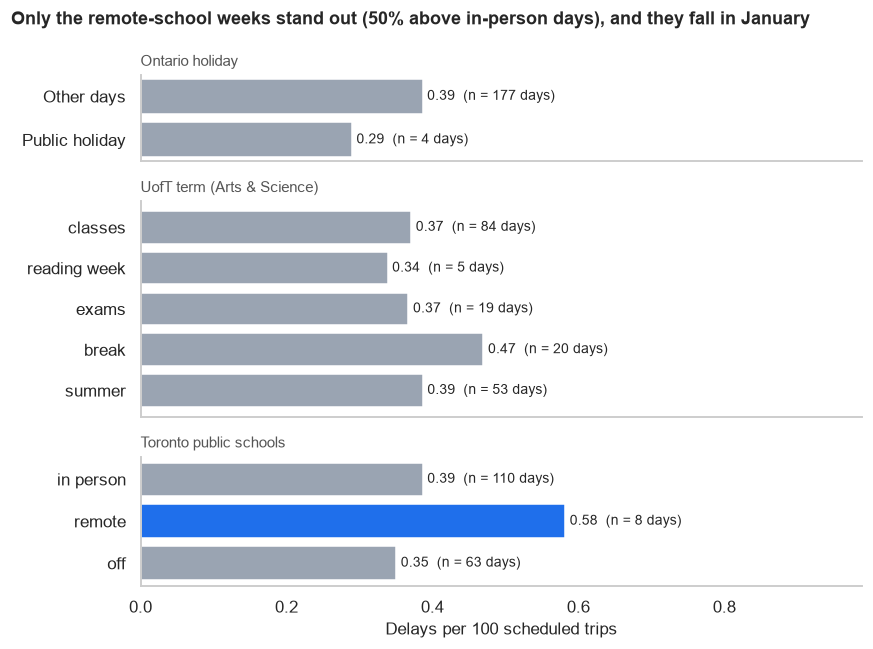

outside January: {'break': 0.38, 'classes': 0.35, 'exams': 0.37, 'reading_week': 0.34, 'summer': 0.39} {'in_person': 0.38, 'off': 0.33} | January vs rest: {False: 0.37, True: 0.48}


In [19]:
cal = [
    ("Ontario holiday", rates("holiday", "date").rename(index={True: "Public holiday", False: "Other days"})),
    ("UofT term (Arts & Science)", rates("uoft_phase", "date").reindex(["classes", "reading_week", "exams", "break", "summer"])),
    ("Toronto public schools", rates("school", "date").reindex(["in_person", "remote", "off"])),
]
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6), height_ratios=[2, 5, 3])
for ax, (label, t) in zip(axes, cal):
    rate_bars(ax, t, "days", accent={"remote"})
    ax.set_title(label, fontsize=10, fontweight="normal", color="#555")
axes[-1].set_xlabel("Delays per 100 scheduled trips")
remote, in_person = cal[2][1].rate["remote"], cal[2][1].rate["in_person"]
fig.suptitle(f"Only the remote-school weeks stand out ({remote / in_person - 1:.0%} above in-person days), and they fall in January",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()
print("outside January:", rates("uoft_phase", "date", rh[~rh.omicron]).rate.round(2).to_dict(),
      rates("school", "date", rh[~rh.omicron]).rate.round(2).to_dict(), "| January vs rest:", rates("omicron", "date").rate.round(2).to_dict())

UofT's "break" looks high only because it includes 1–9 Jan. Outside January, UofT phases sit within a narrow band (0.34–0.39) and school days add little. The calendar effect that matters is January itself, so the `omicron` flag must stay in the model as a control.

## Does bad weather raise the rate?

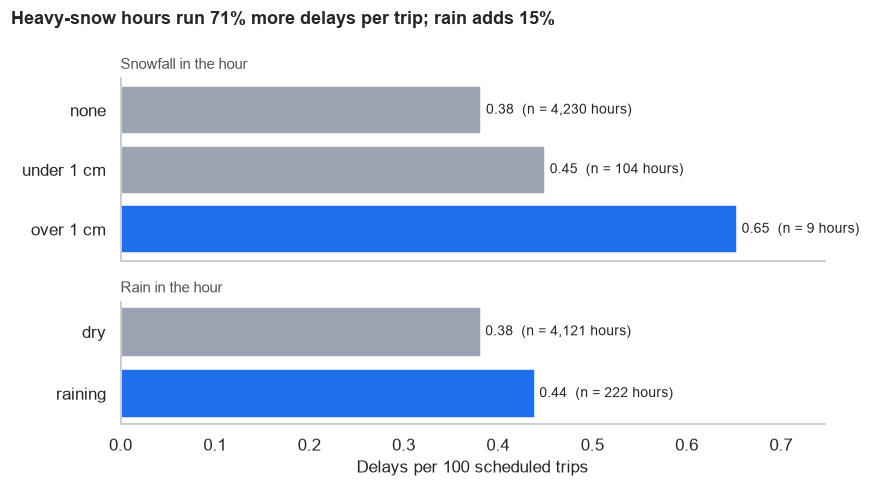

In [20]:
snow = rates(pd.cut(rh.snowfall_cm, [-0.01, 0, 1, 100], labels=["none", "under 1 cm", "over 1 cm"]))
rain = rates(np.where(rh.rain_mm > 0, "raining", "dry")).reindex(["dry", "raining"])
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 4.5), height_ratios=[3, 2])
rate_bars(axes[0], snow, "hours", accent={"over 1 cm"})
rate_bars(axes[1], rain, "hours", accent={"raining"})
axes[0].set_title("Snowfall in the hour", fontsize=10, fontweight="normal", color="#555")
axes[1].set_title("Rain in the hour", fontsize=10, fontweight="normal", color="#555")
axes[1].set_xlabel("Delays per 100 scheduled trips")
fig.suptitle(f"Heavy-snow hours run {snow.rate['over 1 cm'] / snow.rate['none'] - 1:.0%} more delays per trip; rain adds {rain.rate['raining'] / rain.rate['dry'] - 1:.0%}",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

Snow shows the clearest weather effect, but only 9 clock hours had more than 1 cm, all in winter, and the test months (May–June) have none. Rain has many more hours and a smaller lift.

## Which hours are riskiest per trip?

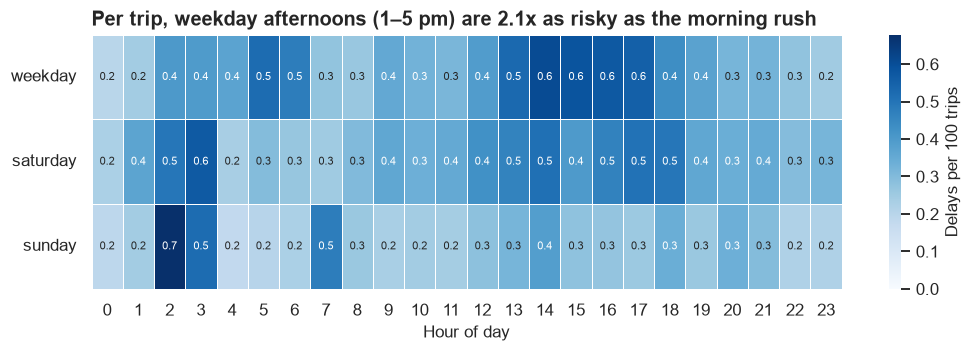

In [21]:
grid_rate = rh.groupby(["day_type", "hour"]).apply(lambda g: 100 * g.n_delays.sum() / g.trips.sum()).unstack().reindex(["weekday", "saturday", "sunday"])
afternoon, morning = grid_rate.loc["weekday", 13:17].mean(), grid_rate.loc["weekday", 7:8].mean()
fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(grid_rate, cmap="Blues", vmin=0, annot=True, fmt=".1f", annot_kws={"fontsize": 7}, linewidths=0.5,
            cbar_kws={"label": "Delays per 100 trips"}, ax=ax)
ax.set(title=f"Per trip, weekday afternoons (1–5 pm) are {afternoon / morning:.1f}x as risky as the morning rush",
       xlabel="Hour of day", ylabel="")
ax.tick_params(axis="y", rotation=0)
plt.show()

Part 1's afternoon peak holds up once service volume is accounted for. The high values at 2–3 am rest on very few trips, so they are noisy.

## Are some kinds of route riskier?

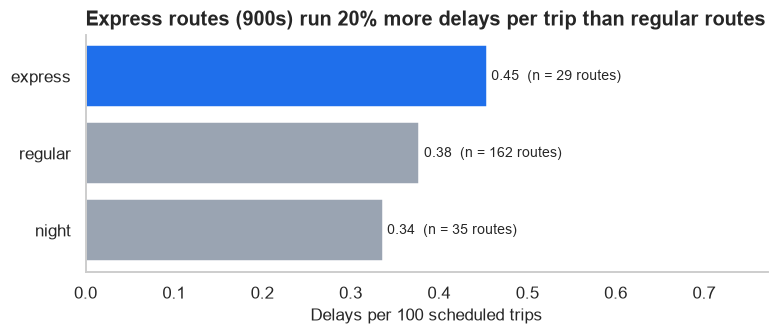

In [22]:
grp = rates("group", "route").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(8, 2.8))
rate_bars(ax, grp, "routes", accent={"express"})
ax.set(title=f"Express routes (900s) run {grp.rate['express'] / grp.rate['regular'] - 1:.0%} more delays per trip than regular routes",
       xlabel="Delays per 100 scheduled trips")
plt.show()

Express routes cover longer distances per trip, so more can go wrong on each one. Night routes (300s) are the calmest.

## Does a recent delay predict the next hour?

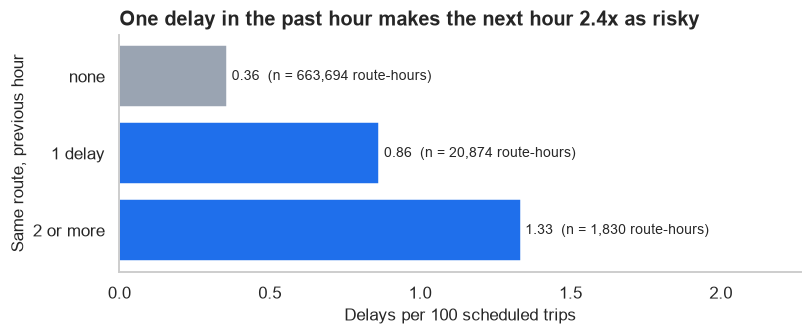

In [23]:
lag = rates(rh.lag1.clip(upper=2).map({0: "none", 1: "1 delay", 2: "2 or more"}), None).reindex(["none", "1 delay", "2 or more"])
fig, ax = plt.subplots(figsize=(8, 2.8))
rate_bars(ax, lag, "route-hours", accent={"1 delay", "2 or more"})
ax.set(title=f"One delay in the past hour makes the next hour {lag.rate['1 delay'] / lag.rate['none']:.1f}x as risky",
       xlabel="Delays per 100 scheduled trips", ylabel="Same route, previous hour")
plt.show()

Recent delays are the strongest single signal here. A model that uses them has to see only the past, which the lag columns guarantee.

## Findings and open questions
- A typical delay is short (median 11 min), but the long tail matters: diversions are ~5% of incidents yet ~28% of delay minutes.
- Operator-related and mechanical incidents are the most frequent causes (~35% and ~29% of incidents).
- Delays peak 2–6 pm and on weekdays; Sundays have roughly 40% fewer than a weekday.
- Weekly volume was highest in January and steady near 1,000/week afterwards.
- Ten routes carry about a quarter of all incidents.


**Part 2: delays per 100 scheduled trips** (overall 0.38; 96.7% of route-hours have no delay)
- A delay on the same route in the past hour is the strongest signal: 2.4x the rate after one delay, 3.7x after two or more.
- Weekday afternoons (1–5 pm) run 2.1x the morning-rush rate, so the afternoon peak is real, not just more buses.
- Heavy snow (over 1 cm in an hour) lifts the rate by about 70%, but only 9 hours qualify; rain adds about 15%.
- Express routes run 20% above regular routes; night routes are the calmest.
- January (Omicron) runs about 30% above the rest of the half-year. Outside it, UofT terms and school days barely move the rate.
- The current schedule matches 98.3% of 2022 delays; 96.2% land in a route-hour with scheduled service.

**Open questions**
- Are diversions mostly planned (construction, events) or unplanned? The log does not say.
- Which routes are worst *per trip or per rider*? Needs ridership or service-hours data.
- What caused the January spike? Per trip it is still 30% higher, so it isn't only weather; staffing shortages are one candidate.
- `Location` is free text; geocoding it would show delay hotspots on a map.